<a href="https://colab.research.google.com/github/Visweash1234/Applied-Data-Science-1/blob/main/Tutorial_8_Wine_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
# Load the dataset
file_path = '/content/wine_dataset_with_headers.csv'
df = pd.read_csv(file_path)

In [6]:
# 1. Check shape
print(f"Dataset shape: {df.shape}")
# Display first few rows to understand structure
display(df.head())


Dataset shape: (178, 14)


,class,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315_of_diluted_wines,proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [7]:
# 2. Check for missing values
missing_values = df.isnull().sum()
print("\nMissing values per column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found.")



Missing values per column:
No missing values found.


In [8]:
# 3. Check feature scales (Descriptive statistics)
print("\nFeature Statistics (Scales Check):")
display(df.describe())


Feature Statistics (Scales Check):


,class,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


### Task 2: PCA on Raw vs. Standardized Data
We will extract the features (excluding the target column `class`) and run PCA twice: once on the unscaled raw features, and once on the standardized features, then compare the variance explained by the first principal component (PC1).

In [9]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Features (excluding 'class' column which represents the cultivar)
X = df.drop(columns=['class'])
y = df['class']

# 1. PCA on raw features
pca_raw = PCA(n_components=2)
pca_raw.fit(X)
raw_pc1_var = pca_raw.explained_variance_ratio_[0]

# 2. PCA on standardized features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca_scaled = PCA(n_components=2)
pca_scaled.fit(X_scaled)
scaled_pc1_var = pca_scaled.explained_variance_ratio_[0]

print(f"PC1 Explained Variance (Raw Data): {raw_pc1_var:.2%}")
print(f"PC1 Explained Variance (Standardized Data): {scaled_pc1_var:.2%}")

PC1 Explained Variance (Raw Data): 99.81%
PC1 Explained Variance (Standardized Data): 36.20%


### Task 3: Scree and Cumulative Variance Plots
We will plot the scree plot and cumulative explained variance. Then, we will use two rules (e.g., Kaiser's Rule of eigenvalues > 1 and the Elbow Method / 80% threshold rule) to select the optimal number of components $k$.

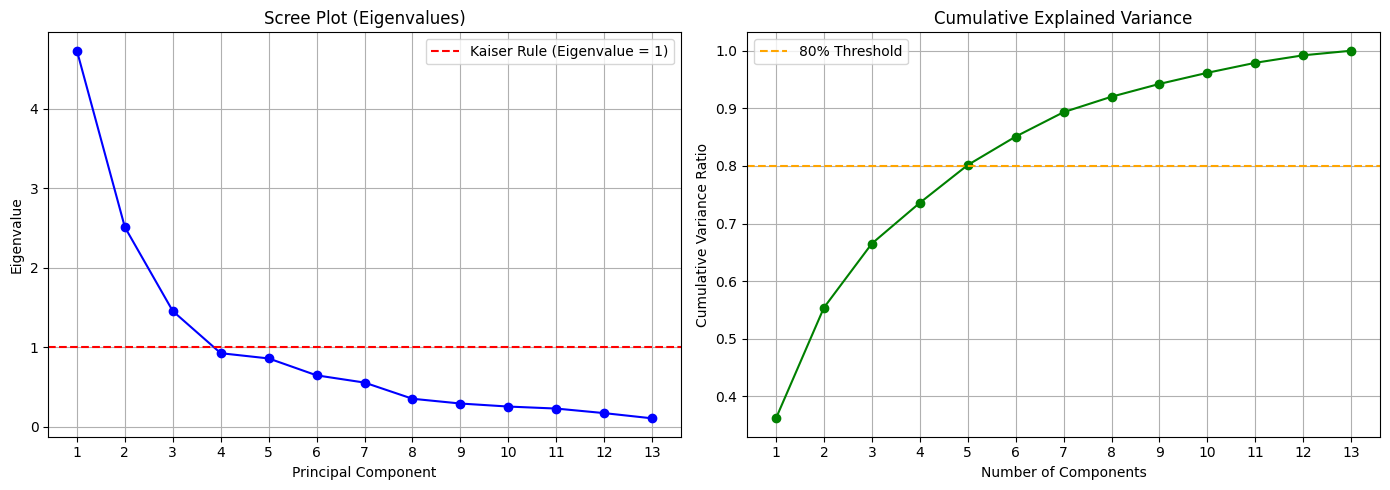

Rule 1: Kaiser's Rule (Eigenvalue > 1) suggests k = 3 components.
Rule 2: Elbow/80% Explained Variance rule suggests k = 5 components.


In [11]:
import matplotlib.pyplot as plt

# Fit PCA with all components on scaled features to evaluate the spectrum
pca_all = PCA().fit(X_scaled)
eigenvalues = pca_all.explained_variance_
explained_variance_ratio = pca_all.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# Create plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scree Plot (Eigenvalues)
ax1.plot(range(1, len(eigenvalues) + 1), eigenvalues, 'o-', color='blue')
ax1.axhline(y=1, color='red', linestyle='--', label="Kaiser Rule (Eigenvalue = 1)")
ax1.set_title("Scree Plot (Eigenvalues)")
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Eigenvalue")
ax1.set_xticks(range(1, len(eigenvalues) + 1))
ax1.legend()
ax1.grid(True)

# Cumulative Variance
ax2.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 'o-', color='green')
ax2.axhline(y=0.8, color='orange', linestyle='--', label="80% Threshold")
ax2.set_title("Cumulative Explained Variance")
ax2.set_xlabel("Number of Components")
ax2.set_ylabel("Cumulative Variance Ratio")
ax2.set_xticks(range(1, len(cumulative_variance) + 1))
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Applying rules
k_kaiser = sum(eigenvalues > 1)
k_elbow = np.argmax(cumulative_variance >= 0.8) + 1

print(f"Rule 1: Kaiser's Rule (Eigenvalue > 1) suggests k = {k_kaiser} components.")
print(f"Rule 2: Elbow/80% Explained Variance rule suggests k = {k_elbow} components.")

### Task 4: Biplot (PC1 vs. PC2 with Loading Arrows)
Now we project the standardized data onto the first two principal components, color the points by cultivar, and overlay the feature loading vectors.

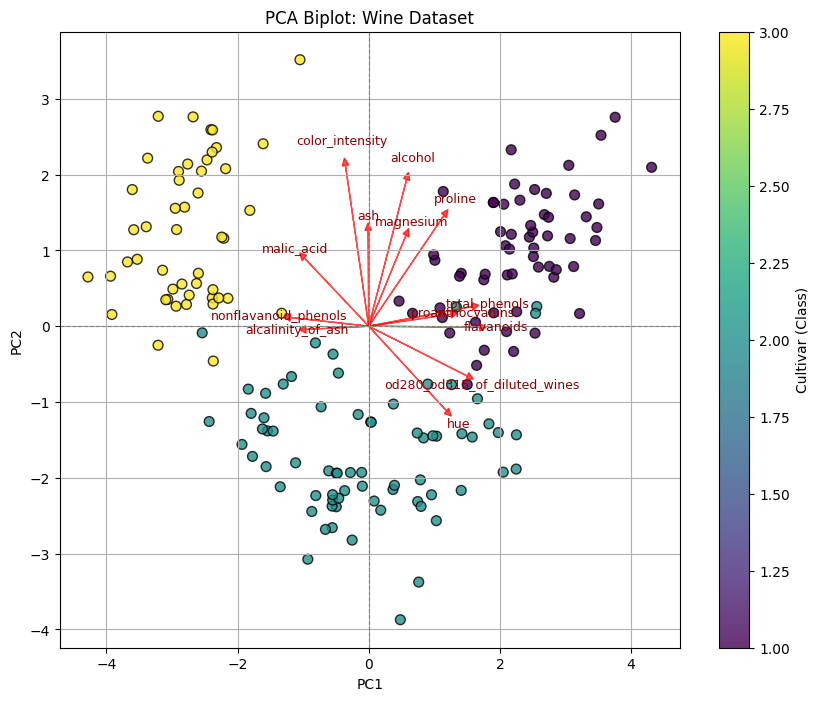

In [12]:
# Project data
X_pca = pca_scaled.transform(X_scaled)
pc1 = X_pca[:, 0]
pc2 = X_pca[:, 1]

# Get feature loading vectors for PC1 and PC2
loadings = pca_scaled.components_.T

plt.figure(figsize=(10, 8))

# Scatter plot colored by cultivar
scatter = plt.scatter(pc1, pc2, c=y, cmap='viridis', alpha=0.8, edgecolor='k', s=50)
plt.colorbar(scatter, label='Cultivar (Class)')

# Scaling factor to fit loading arrows to the coordinate system of the scores
scale_arrow = 4.0

# Plot loadings
for i, feature in enumerate(X.columns):
    plt.arrow(0, 0, loadings[i, 0] * scale_arrow, loadings[i, 1] * scale_arrow,
              color='red', alpha=0.7, head_width=0.1, head_length=0.1)
    plt.text(loadings[i, 0] * scale_arrow * 1.15, loadings[i, 1] * scale_arrow * 1.15,
             feature, color='darkred', ha='center', va='center', fontsize=9)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot: Wine Dataset")
plt.grid(True)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
plt.show()

### Task 5: Interpret and Name PC1 & PC2
Let's view the exact loading values for PC1 and PC2 to identify the dominant contributing features.

In [13]:
df_loadings = pd.DataFrame(
    data=pca_scaled.components_[:2].T,
    columns=['PC1_Loadings', 'PC2_Loadings'],
    index=X.columns
)
display(df_loadings.sort_values(by='PC1_Loadings', ascending=False))

,PC1_Loadings,PC2_Loadings
flavanoids,0.422934,-0.003360
total_phenols,0.394661,0.065040
od280_od315_of_diluted_wines,0.376167,-0.164496
proanthocyanins,0.313429,0.039302
hue,0.296715,-0.279235
proline,0.286752,0.364903
alcohol,0.144329,0.483652
magnesium,0.141992,0.299634
ash,-0.002051,0.316069
color_intensity,-0.088617,0.529996


### Task 6: K-means (k=3) Clustering Comparison using ARI
We run K-means with $k=3$ on two configurations:
1. The complete standardized features ($13$ dimensions)
2. The first $2$ Principal Components

We then compare how well each clustering matches the true cultivar labels using the Adjusted Rand Index (ARI).

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# 1. K-means on Full Scaled Features
kmeans_full = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_full = kmeans_full.fit_predict(X_scaled)
ari_full = adjusted_rand_score(y, clusters_full)

# 2. K-means on 2 PCs
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_pca = kmeans_pca.fit_predict(X_pca)
ari_pca = adjusted_rand_score(y, clusters_pca)

print(f"Adjusted Rand Index (ARI) on Full Standardized Features: {ari_full:.4f}")
print(f"Adjusted Rand Index (ARI) on 2 Principal Components: {ari_pca:.4f}")

Adjusted Rand Index (ARI) on Full Standardized Features: 0.8975
Adjusted Rand Index (ARI) on 2 Principal Components: 0.8951
